In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

In [2]:
# Configuración de dispositivo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
# Definir las transformaciones (normalización)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))  # Normalización de la imagen
])

In [4]:
# Cargar MNIST
trainset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
testset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

trainloader = DataLoader(trainset, batch_size=128, shuffle=True)
testloader = DataLoader(testset, batch_size=128, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 478kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.43MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.27MB/s]


In [5]:
# Definir el modelo CNN
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)  # Conv2D: 1 canal de entrada, 32 de salida
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)  # Capa totalmente conectada
        self.fc2 = nn.Linear(128, 10)  # Salida con 10 clases (0-9)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))  # ReLU y MaxPool
        x = self.pool(torch.relu(self.conv2(x)))  # ReLU y MaxPool
        x = x.view(-1, 64 * 7 * 7)  # Aplanar para la capa fully connected
        x = torch.relu(self.fc1(x))  # Capa oculta
        x = self.fc2(x)  # Capa de salida
        return x

In [6]:
# Instanciar el modelo y mover a dispositivo (CPU o GPU)
model = CNN().to(device)

In [7]:
# Definir el criterio (función de pérdida) y el optimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [8]:
# Función de entrenamiento
def train(model, trainloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()  # Limpiar los gradientes del optimizador
        outputs = model(inputs)  # Forward pass
        loss = criterion(outputs, labels)  # Calcular la pérdida
        loss.backward()  # Backward pass
        optimizer.step()  # Actualizar los pesos

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(trainloader)
    accuracy = 100 * correct / total
    return epoch_loss, accuracy

In [9]:
# Función de evaluación
def evaluate(model, testloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_loss = running_loss / len(testloader)
    accuracy = 100 * correct / total
    return test_loss, accuracy

In [10]:
# Entrenamiento del modelo
num_epochs = 10
train_losses, test_losses, train_accuracies, test_accuracies = [], [], [], []

for epoch in range(num_epochs):
    train_loss, train_acc = train(model, trainloader, criterion, optimizer, device)
    test_loss, test_acc = evaluate(model, testloader, criterion, device)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Test Loss: {test_loss:.4f}, "
          f"Train Accuracy: {train_acc:.2f}%, Test Accuracy: {test_acc:.2f}%")

Epoch 1/10, Train Loss: 0.1895, Test Loss: 0.0478, Train Accuracy: 94.41%, Test Accuracy: 98.35%
Epoch 2/10, Train Loss: 0.0510, Test Loss: 0.0414, Train Accuracy: 98.41%, Test Accuracy: 98.59%
Epoch 3/10, Train Loss: 0.0343, Test Loss: 0.0323, Train Accuracy: 98.93%, Test Accuracy: 98.94%
Epoch 4/10, Train Loss: 0.0271, Test Loss: 0.0306, Train Accuracy: 99.17%, Test Accuracy: 98.98%
Epoch 5/10, Train Loss: 0.0207, Test Loss: 0.0277, Train Accuracy: 99.31%, Test Accuracy: 99.16%
Epoch 6/10, Train Loss: 0.0167, Test Loss: 0.0330, Train Accuracy: 99.46%, Test Accuracy: 98.89%
Epoch 7/10, Train Loss: 0.0135, Test Loss: 0.0294, Train Accuracy: 99.57%, Test Accuracy: 99.03%
Epoch 8/10, Train Loss: 0.0101, Test Loss: 0.0333, Train Accuracy: 99.67%, Test Accuracy: 99.06%
Epoch 9/10, Train Loss: 0.0092, Test Loss: 0.0375, Train Accuracy: 99.70%, Test Accuracy: 98.84%
Epoch 10/10, Train Loss: 0.0079, Test Loss: 0.0300, Train Accuracy: 99.70%, Test Accuracy: 99.13%


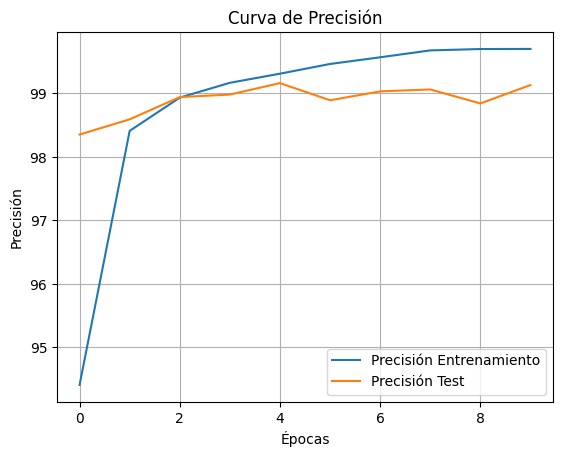

In [11]:
# Gráficas de precisión
plt.plot(train_accuracies, label='Precisión Entrenamiento')
plt.plot(test_accuracies, label='Precisión Test')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid()
plt.title('Curva de Precisión')
plt.show()

In [12]:
# Resultados finales
print("\n🔍 Resultados Finales")
print(f"Precisión Final en Test: {test_accuracies[-1]:.2f}%")


🔍 Resultados Finales
Precisión Final en Test: 99.13%


Sugerencias:

* ¿Qué sucede si cambian optim.Adam por optim.SGD? ¿Cómo impacta la precisión?
* ¿Cómo afectaría el rendimiento si aumentan el número de épocas a 20?
* ¿Qué cambios notarían si usan un learning rate más pequeño o más grande?